# TP3 - Desarrollo y comparacion de modelos

## Objetivo

El objetivo es estimar la probabilidad de pago de cada solicitud y utilizarla para seleccionar prestamos sin superar un presupuesto de USD 2.000.000.

El notebook presenta los modelos que funcionaron y tambien los experimentos descartados. En cada caso indicamos que quisimos probar, que resultado obtuvimos y que decision tomamos.

## 1. Preparacion comun de los datos

La preparacion se realiza una sola vez y luego se reutiliza en todos los modelos. Para evitar informacion futura, cada solicitud se relaciona solamente con los registros bancarios anteriores a su fecha.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

solicitudes_train = pd.read_csv("data/solicitudes_train.csv")
comportamiento_bancario = pd.read_csv("data/comportamiento_bancario.csv")

In [2]:
solicitudes_train["Fecha_Solicitud"] = pd.to_datetime(
    solicitudes_train["Fecha_Solicitud"]
)

print("Usuarios distintos:", solicitudes_train["ID_Usuario"].nunique())

print("Filas duplicadas:", solicitudes_train.duplicated().sum())


print("\nPeriodo:", solicitudes_train["Fecha_Solicitud"].min().date(),
      "a", solicitudes_train["Fecha_Solicitud"].max().date())

print("Maximo de solicitudes de un usuario:",
      solicitudes_train.groupby("ID_Usuario").size().max())

Usuarios distintos: 18548
Filas duplicadas: 0

Periodo: 2025-01-01 a 2025-12-01
Maximo de solicitudes de un usuario: 8


In [3]:
comportamiento_bancario["Mes_Referencia"] = pd.to_datetime(
    comportamiento_bancario["Mes_Referencia"]
)

print("Usuarios distintos:", comportamiento_bancario["ID_Usuario"].nunique())
print("Periodo:", comportamiento_bancario["Mes_Referencia"].min().date(),
      "a", comportamiento_bancario["Mes_Referencia"].max().date())

meses_por_usuario = comportamiento_bancario.groupby(
    "ID_Usuario"
)["Mes_Referencia"].nunique()

print("\nMeses disponibles por usuario:")
display(meses_por_usuario.describe().round(2))

Usuarios distintos: 28993
Periodo: 2024-01-01 a 2025-12-01

Meses disponibles por usuario:


count    28993.00
mean        22.80
std          1.07
min         17.00
25%         22.00
50%         23.00
75%         24.00
max         24.00
Name: Mes_Referencia, dtype: float64

In [4]:
historial_solicitudes = solicitudes_train.merge(
    comportamiento_bancario,
    on="ID_Usuario",
    how="left"
)

print("Filas de solicitudes:", len(solicitudes_train))
print("Filas despues del merge:", len(historial_solicitudes))

Filas de solicitudes: 32416
Filas despues del merge: 739137


In [5]:
historial_solicitudes = historial_solicitudes[
    historial_solicitudes["Mes_Referencia"]
    < historial_solicitudes["Fecha_Solicitud"]
].copy()

print("Filas despues del filtro temporal:", len(historial_solicitudes))
print("Solicitudes distintas:", historial_solicitudes["ID_Solicitud"].nunique())

Filas despues del filtro temporal: 538638
Solicitudes distintas: 32416


In [6]:
historial_ordenado = historial_solicitudes.sort_values(
    ["ID_Solicitud", "Mes_Referencia"]
)

resumen_historial = historial_ordenado.groupby("ID_Solicitud").agg(
    meses_historial=("Mes_Referencia", "count"),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean"),
    saldo_inicial=("Saldo_Promedio_Mensual", "first"),
    saldo_final=("Saldo_Promedio_Mensual", "last"),
    atraso_promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    atraso_maximo=("Dias_Atraso_Otras_Deudas", "max")
).reset_index()

resumen_historial.head()

,ID_Solicitud,meses_historial,saldo_promedio,saldo_inicial,saldo_final,atraso_promedio,atraso_maximo
0,1,14,3695.225714,3712.29,3352.35,4.857143,25
1,2,21,5976.456667,3807.48,5054.62,8.809524,56
2,3,15,178.574667,203.23,178.46,20.733333,57
3,4,18,7589.356667,6543.97,7372.57,0.944444,4
4,5,12,3888.616667,4848.48,2952.59,3.750000,32


In [7]:
datos_modelo = solicitudes_train.merge(
    resumen_historial,
    on="ID_Solicitud",
    how="left",
    validate="one_to_one"
)

saldo_inicial_seguro = datos_modelo["saldo_inicial"].mask(
    datos_modelo["saldo_inicial"].eq(0)
)
saldo_promedio_seguro = datos_modelo["saldo_promedio"].mask(
    datos_modelo["saldo_promedio"].eq(0)
)

datos_modelo["ratio_tendencia_saldo"] = (
    datos_modelo["saldo_final"] / saldo_inicial_seguro
)
datos_modelo["ratio_prestamo_ingreso"] = (
    datos_modelo["Monto_Solicitado"] / datos_modelo["Ingreso_Mensual"]
)
datos_modelo["ratio_prestamo_saldo"] = (
    datos_modelo["Monto_Solicitado"] / saldo_promedio_seguro
)

datos_modelo = datos_modelo.drop(columns="saldo_inicial")

print("Filas del dataset preparado:", len(datos_modelo))
print("Solicitudes distintas:", datos_modelo["ID_Solicitud"].nunique())
datos_modelo.head()

Filas del dataset preparado: 32416
Solicitudes distintas: 32416


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,meses_historial,saldo_promedio,saldo_final,atraso_promedio,atraso_maximo,ratio_tendencia_saldo,ratio_prestamo_ingreso,ratio_prestamo_saldo
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,14,3695.225714,3352.35,4.857143,25,0.903041,1.770903,2.137894
1,2,20744,17400,0.2507,3889,Vivienda,2025-12-01,1,21,5976.456667,5054.62,8.809524,56,1.327550,4.474158,2.911424
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06-01,0,15,178.574667,178.46,20.733333,57,0.878118,2.131351,48.159127
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07-01,1,18,7589.356667,7372.57,0.944444,4,1.126620,3.310105,1.752454
4,5,24719,6600,0.2314,3357,Otros,2025-01-01,1,12,3888.616667,2952.59,3.750000,32,0.608972,1.966041,1.697262


In [8]:
datos_modelo[[
    "ratio_prestamo_ingreso",
    "ratio_prestamo_saldo",
    "ratio_tendencia_saldo"
]].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])

,ratio_prestamo_ingreso,ratio_prestamo_saldo,ratio_tendencia_saldo
count,32416.000000,32416.000000,32416.000000
mean,3.439613,14.551608,1.105596
std,2.425354,73.067997,0.539219
min,0.123122,0.068209,0.113253
1%,0.612282,0.359758,0.324540
5%,0.964803,0.623646,0.465906
50%,2.799969,2.522912,1.002416
95%,8.166632,28.115860,2.093306
99%,12.217510,342.112035,2.960705
max,55.142018,1897.614428,8.252326


### Transformacion logaritmica de los ratios

Al revisar los percentiles observamos que los ratios presentaban distribuciones asimetricas y algunos valores extremadamente altos, especialmente `ratio_prestamo_saldo`. Su mediana era cercana a 2.52, mientras que el percentil 99 superaba 342 y el valor maximo llegaba aproximadamente a 1897.

Por este motivo aplicamos una transformacion logaritmica. Esta transformacion comprime los valores extremos y reduce la distancia con el resto de las observaciones, pero conserva su orden. No se trata de una normalizacion entre 0 y 1.

Para `ratio_prestamo_ingreso` y `ratio_prestamo_saldo` utilizamos `log1p`, que calcula `log(1 + x)` y permite trabajar tambien con valores iguales a cero.

Para `ratio_tendencia_saldo` utilizamos el logaritmo natural. De esta manera, un resultado positivo representa un aumento del saldo, cero representa estabilidad y un resultado negativo representa una disminucion.

En los modelos basados en arboles esta transformacion no es indispensable, porque el orden de los valores no cambia. En este trabajo tambien sirve para representar los ratios de una forma mas controlada y facil de analizar.

In [9]:
datos_modelo["log_ratio_prestamo_ingreso"] = np.log1p(
    datos_modelo["ratio_prestamo_ingreso"]
)

datos_modelo["log_ratio_prestamo_saldo"] = np.log1p(
    datos_modelo["ratio_prestamo_saldo"]
)

datos_modelo["log_ratio_tendencia_saldo"] = np.log(
    datos_modelo["ratio_tendencia_saldo"]
)

In [10]:
print("Filas del dataset:", len(datos_modelo))
print("Solicitudes unicas:", datos_modelo["ID_Solicitud"].nunique())
print("Valores faltantes:", datos_modelo.isna().sum().sum())
print(
    "Valores infinitos:",
    np.isinf(
        datos_modelo.select_dtypes(include="number")
    ).sum().sum()
)
print(
    "Todos los meses son anteriores:",
    (
        historial_solicitudes["Mes_Referencia"]
        < historial_solicitudes["Fecha_Solicitud"]
    ).all()
)

Filas del dataset: 32416
Solicitudes unicas: 32416
Valores faltantes: 0
Valores infinitos: 0
Todos los meses son anteriores: True


### Division de entrenamiento y validacion

La division se realiza por `ID_Usuario`. De esta manera, las solicitudes de una misma persona no aparecen en ambos conjuntos. El One Hot Encoding se ajusta dentro del pipeline utilizando solamente los datos de entrenamiento.

In [11]:
from sklearn.model_selection import GroupShuffleSplit

columnas_excluidas = [
    "Estado_Final",
    "ID_Solicitud",
    "ID_Usuario",
    "Fecha_Solicitud",
    "ratio_prestamo_ingreso",
    "ratio_prestamo_saldo",
    "ratio_tendencia_saldo"     # aca sacamos estos porque nos quedamos con los logaritmos
]

X = datos_modelo.drop(columns=columnas_excluidas).copy()
y = datos_modelo["Estado_Final"].copy()
grupos = datos_modelo["ID_Usuario"].copy() # estos sirven para no mezclar los datos de un mismo usuario entre train y validacion

separador = GroupShuffleSplit(  # esto es para separar los datos en train y validacion, asegurando que los datos de un mismo usuario no se mezclen entre ambos conjuntos
    n_splits=1,
    test_size=0.30,
    random_state=42
)

indices_train, indices_validacion = next(
    separador.split(X, y, groups=grupos)
)

X_train = X.iloc[indices_train].copy()
X_validacion = X.iloc[indices_validacion].copy()
y_train = y.iloc[indices_train].copy()
y_validacion = y.iloc[indices_validacion].copy()

validacion_completa = datos_modelo.iloc[indices_validacion].copy() # creamos un dataset con todas las columnas para poder analizar los resultados de la validacion

In [12]:
usuarios_train = set(grupos.iloc[indices_train])
usuarios_validacion = set(grupos.iloc[indices_validacion])

print("Filas de entrenamiento:", len(X_train))
print("Filas de validacion:", len(X_validacion))
print("Usuarios compartidos:",
      len(usuarios_train.intersection(usuarios_validacion)))
print("Porcentaje de pago en entrenamiento:",
      round(y_train.mean() * 100, 2))
print("Porcentaje de pago en validacion:",
      round(y_validacion.mean() * 100, 2))

Filas de entrenamiento: 22562
Filas de validacion: 9854
Usuarios compartidos: 0
Porcentaje de pago en entrenamiento: 84.09
Porcentaje de pago en validacion: 83.95


In [13]:
columnas_categoricas = ["Motivo_Prestamo"]
columnas_numericas = [
    columna for columna in X_train.columns
    if columna not in columnas_categoricas
]

print("Columnas numericas:", columnas_numericas)
print("Columnas categoricas:", columnas_categoricas)

Columnas numericas: ['Monto_Solicitado', 'Tasa_Interes', 'Ingreso_Mensual', 'meses_historial', 'saldo_promedio', 'saldo_final', 'atraso_promedio', 'atraso_maximo', 'log_ratio_prestamo_ingreso', 'log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']
Columnas categoricas: ['Motivo_Prestamo']


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preparacion_arbol = ColumnTransformer([ # permite aplicar una transformacion diferente segun el tipo de columna
    (
        "motivo",                               # nombre de la transformacion
        OneHotEncoder(handle_unknown="ignore"), # evita un error si aparece un motivo nuevo
        columnas_categoricas                    # se lo aplicamos a las columnas categoricas
    ),
    (
        "numericas",
        "passthrough",      # deja las columnas numericas como estan
        columnas_numericas  # se lo aplicamos a las columnas numericas
    )
])

## 2. Experimentos con arboles de decision

### Experimento 1: arbol simple

Probamos un arbol con profundidad maxima de 3 para obtener un modelo sencillo que sirva como punto de partida.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

arbol_inicial = Pipeline([                  # esto conecta los pasos (nombre del paso, objeto que lo hace) de adentro en un pipe
    ("preparacion", preparacion_arbol),     # preparacion del paso anteorior (onehot y dejar las numericas como estaban)
    (
        "modelo",                           # crea el arbol (se trae lo del paso anterior)
        DecisionTreeClassifier(
            max_depth=3,            # 3 niveles
            random_state=42         # semilla
        )
    )
])

arbol_inicial.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('motivo', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [16]:
from sklearn.metrics import roc_auc_score, brier_score_loss

# Buscamos la columna correspondiente a Estado_Final = 1 (Pagado)
indice_pagado = list(
    arbol_inicial.named_steps["modelo"].classes_    # named_steps nos permite acceder a los pasos del pipeline, en este caso al modelo de arbol de decision, y classes_ nos da las clases que predice el modelo
).index(1)                                          # nos devuelve el indice de la clase 1 (pagado) en la lista de clases que predice el modelo

probabilidades_train = arbol_inicial.predict_proba(         # calcula las probabilidades de cada clase para cada fila del dataset
    X_train
)[:, indice_pagado] # agarramos solo la columna de la clase 1 (pagado) para cada fila, que es lo que nos interesa

# ejemplo, el modelo devuleve: [ [0.20, 0.80], [0.70, 0.30] ] y se toma [0.80, 0.30]

probabilidades_validacion = arbol_inicial.predict_proba(    # lo mismo que arriba pero para el conjunto de validacion
    X_validacion
)[:, indice_pagado]

resultados_iniciales = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validacion"],
    "ROC AUC": [
        roc_auc_score(y_train, probabilidades_train),
        roc_auc_score(y_validacion, probabilidades_validacion)
    ],
    "Brier score": [
        brier_score_loss(y_train, probabilidades_train),
        brier_score_loss(y_validacion, probabilidades_validacion)
    ]
})

resultados_iniciales.round(4)

# ROC AUC: mas alto es mejor. Un valor de 0,5 equivale a una separacion al azar; 1 representa una separacion perfecta
# Brier score: mas bajo es mejor. Penaliza las diferencias entre las probabilidades y lo que realmente ocurrio

,Conjunto,ROC AUC,Brier score
0,Entrenamiento,0.8163,0.1022
1,Validacion,0.8142,0.1023


El modelo obtuvo un ROC AUC de validacion de 0.8142. Sirve como primera referencia, pero todavia tiene margen de mejora.

### Experimento 2: arbol sin limite

Quitamos el limite de profundidad para comprobar si un arbol mas complejo aprende mejores reglas.

In [17]:
from sklearn.base import clone                      # apra hacer una preparacion nueva sin entrenar

# Creamos una copia sin entrenar de la preparacion
arbol_libre = Pipeline([
    ("preparacion", clone(preparacion_arbol)),
    (
        "modelo",
        DecisionTreeClassifier(random_state=42)
        # sin max_depth, para que el arbol se entrene hasta que todas las hojas sean puras (o hasta que no haya mas datos para separar)
    )
])

arbol_libre.fit(X_train, y_train)

indice_pagado_libre = list(
    arbol_libre.named_steps["modelo"].classes_
).index(1)

probabilidades_train_libre = arbol_libre.predict_proba(
    X_train
)[:, indice_pagado_libre]

probabilidades_validacion_libre = arbol_libre.predict_proba(
    X_validacion
)[:, indice_pagado_libre]

resultados_libre = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validacion"],
    "ROC AUC": [
        roc_auc_score(y_train, probabilidades_train_libre),
        roc_auc_score(y_validacion, probabilidades_validacion_libre)
    ],
    "Brier score": [
        brier_score_loss(y_train, probabilidades_train_libre),
        brier_score_loss(y_validacion, probabilidades_validacion_libre)
    ]
})

resultados_libre.round(4)

,Conjunto,ROC AUC,Brier score
0,Entrenamiento,1.0000,0.0000
1,Validacion,0.6282,0.2092


Este experimento no resulto. El arbol obtuvo un ROC AUC de 1.0000 en entrenamiento y 0.6282 en validacion. Aprendio perfectamente los datos conocidos, pero no pudo generalizar. Lo descartamos por sobreajuste.

### Experimento 3: arbol ajustado

Buscamos un punto intermedio probando distintas profundidades y cantidades minimas de solicitudes por hoja. La busqueda se realiza solamente dentro de entrenamiento y mantiene separados a los usuarios mediante `GroupKFold`.

In [18]:
from sklearn.model_selection import GridSearchCV, GroupKFold

# Pipeline nuevo, sin entrenar
arbol_busqueda = Pipeline([
    ("preparacion", clone(preparacion_arbol)),
    (
        "modelo",
        DecisionTreeClassifier(random_state=42)
    )
])

# Combinaciones que vamos a comparar
parametros = {
    "modelo__max_depth": [3, 5, 8, None],       # cambia max_depth del paso llamado "modelo" dentro del pipeline.
    "modelo__min_samples_leaf": [20, 50, 100]
    # van a ser 12 configuraciones en total 4 depth x 3 min_samples_leaf
}

# Usuarios correspondientes a las filas de entrenamiento
grupos_train = grupos.iloc[indices_train]

# Tres divisiones internas, sin compartir usuarios
divisiones = GroupKFold(n_splits=3) # esto se usa depues, es solo la estrageia de division, no la division en si

# En cada ronda se utiliza una parte para validar y las otras dos para entrenar:
# Ronda 1: partes 2 y 3 entrenan | parte 1 valida
# Ronda 2: partes 1 y 3 entrenan | parte 2 valida
# Ronda 3: partes 1 y 2 entrenan | parte 3 valida

busqueda_arbol = GridSearchCV(      # GridSearchCV prueba distintas configuraciones del arbol para encontrar la que obtiene mejores resultados. 
    estimator=arbol_busqueda,       # estimador es el pipeline que queremos entrenar y optimizar
    param_grid=parametros,          # diccionario con las combinaciones de parametros que queremos probar
    scoring={
        "auc": "roc_auc",
        "brier": "neg_brier_score"  # devuelve el brier con signo negativo porque la busqueda elige el valor mas alto
    },
    refit="brier",
    cv=divisiones,
    return_train_score=True
)

busqueda_arbol.fit(
    X_train,
    y_train,
    groups=grupos_train
)

# En este punto comienza la busqueda:
#    1. Forma las tres divisiones respetando los usuarios.
#    2. Prueba todas las combinaciones de parametros.
#    3. Entrena cada combinacion tres veces.
#    4. Calcula ROC AUC y Brier score.
#    5. Promedia los resultados de las tres pruebas.
#    6. Elige la configuracion con el mejor Brier score.
#    7. Vuelve a entrenar esa configuracion usando todo el conjunto de entrenamiento.

print("Mejores parametros:")
print(busqueda_arbol.best_params_)

print(
    "\nBrier promedio en las pruebas internas:",
    round(-busqueda_arbol.best_score_, 4)
)

Mejores parametros:
{'modelo__max_depth': 5, 'modelo__min_samples_leaf': 100}

Brier promedio en las pruebas internas: 0.1019


In [19]:
# La busqueda ya entreno este modelo con todo X_train
arbol_ajustado = busqueda_arbol.best_estimator_ # Recupera la mejor configuracion encontrada por GridSearchCV (mejor Brier), ejemplo: {'modelo__max_depth': 5, 'modelo__min_samples_leaf': 100}

indice_pagado_ajustado = list(                      # identificar que columna de predict_proba() contiene la probabilidad de pago.
    arbol_ajustado.named_steps["modelo"].classes_
).index(1)

probabilidades_train_ajustado = arbol_ajustado.predict_proba(
    X_train
)[:, indice_pagado_ajustado]    # Calcula la probabilidad de pago de cada solicitud del conjunto de entrenamiento, devuelve algo como [ [0.20, 0.80], [0.70, 0.30] ] y se toma [0.80, 0.30]

probabilidades_validacion_ajustado = arbol_ajustado.predict_proba(
    X_validacion
)[:, indice_pagado_ajustado]

comparacion_arboles = pd.DataFrame({        # los vemos todos juntos para comparar
    "Modelo": [
        "Profundidad 3",
        "Sin limite",
        "Profundidad 5, minimo 100 por hoja"
    ],
    "AUC entrenamiento": [
        roc_auc_score(y_train, probabilidades_train),
        roc_auc_score(y_train, probabilidades_train_libre),
        roc_auc_score(y_train, probabilidades_train_ajustado)
    ],
    "AUC validacion": [
        roc_auc_score(y_validacion, probabilidades_validacion),
        roc_auc_score(y_validacion, probabilidades_validacion_libre),
        roc_auc_score(y_validacion, probabilidades_validacion_ajustado)
    ],
    "Brier entrenamiento": [
        brier_score_loss(y_train, probabilidades_train),
        brier_score_loss(y_train, probabilidades_train_libre),
        brier_score_loss(y_train, probabilidades_train_ajustado)
    ],
    "Brier validacion": [
        brier_score_loss(y_validacion, probabilidades_validacion),
        brier_score_loss(y_validacion, probabilidades_validacion_libre),
        brier_score_loss(y_validacion, probabilidades_validacion_ajustado)
    ]
})

comparacion_arboles.round(4)

,Modelo,AUC entrenamiento,AUC validacion,Brier entrenamiento,Brier validacion
0,Profundidad 3,0.8163,0.8142,0.1022,0.1023
1,Sin limite,1.0000,0.6282,0.0000,0.2092
2,"Profundidad 5, minimo 100 por hoja",0.8387,0.8348,0.0986,0.1001


La mejor configuracion fue `max_depth=5` y `min_samples_leaf=100`. Obtuvo un ROC AUC de validacion de 0.8348 y queda como modelo de referencia para los ensambles.

## 3. Experimentos con modelos de ensamble

Todos los modelos utilizan la misma division y la misma preparacion. Esto permite compararlos sobre las mismas solicitudes.

In [20]:
auc_arbol_referencia = roc_auc_score(
    y_validacion,
    probabilidades_validacion_ajustado
)

print(
    "ROC AUC del arbol de referencia:",
    round(auc_arbol_referencia, 4)
)

ROC AUC del arbol de referencia: 0.8348


### Experimento 4: Bagging

Entrenamos 100 arboles con diferentes muestras bootstrap y combinamos sus probabilidades para reducir la variabilidad del arbol individual.

In [21]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

bagging = Pipeline([
    (
        "preparacion",
        clone(preparacion_arbol)
    ),
    (
        "modelo",
        BaggingClassifier(
            DecisionTreeClassifier(
                max_depth=6,
                random_state=42
            ),
            n_estimators=100,
            random_state=42
        )
    )
])

bagging.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('motivo', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [22]:
# Evaluamos

probabilidades_bagging = bagging.predict_proba(
    X_validacion
)[:, 1] # sacamos la columna de la clase 1 (pagado) para cada fila, que es lo que nos interesa

auc_bagging = roc_auc_score(
    y_validacion,               #resultados reales de validacion
    probabilidades_bagging      #probabilidades de pago predichas por el modelo
)                               

print(
    "ROC AUC del arbol de referencia:",
    round(auc_arbol_referencia, 4)      #auc del arbol de referencia, que es el arbol ajustado con max_depth=5 y min_samples_leaf=100
)

print(
    "ROC AUC de Bagging:",
    round(auc_bagging, 4)               #auc del modelo de Bagging, que es un ensamble de arboles de decision con max_depth=6 y 100 estimadores
)

ROC AUC del arbol de referencia: 0.8348
ROC AUC de Bagging: 0.842


In [23]:
probabilidades_bagging

array([0.51427697, 0.95219795, 0.92705988, ..., 0.9425756 , 0.54000704,
       0.9743495 ], shape=(9854,))

Bagging obtuvo 0.8420 de ROC AUC. Supero al arbol de referencia por 0.0072.

### Experimento 5: Random Forest

Random Forest agrega aleatoriedad sobre las variables consideradas en cada corte. Esperamos obtener arboles menos parecidos entre si.

In [24]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    (
        "preparacion",
        clone(preparacion_arbol)
    ),
    (
        "modelo",
        RandomForestClassifier(
            max_depth=6,
            n_estimators=100,
            random_state=42
        )
    )
])

random_forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('motivo', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [25]:
probabilidades_random_forest = random_forest.predict_proba(
    X_validacion
)[:, 1]

auc_random_forest = roc_auc_score(
    y_validacion,
    probabilidades_random_forest
)

print(
    "ROC AUC del arbol de referencia:",
    round(auc_arbol_referencia, 4)
)

print(
    "ROC AUC de Bagging:",
    round(auc_bagging, 4)
)

print(
    "ROC AUC de Random Forest:",
    round(auc_random_forest, 4)
)

ROC AUC del arbol de referencia: 0.8348
ROC AUC de Bagging: 0.842
ROC AUC de Random Forest: 0.8405


Random Forest obtuvo 0.8405 de ROC AUC. Mejoro al arbol individual, pero quedo apenas por debajo de Bagging.

### Experimento 6: Random Forest con 300 arboles

Probamos si aumentar de 100 a 300 arboles produce una mejora importante. Tambien activamos la evaluacion interna Out-of-Bag. El valor OOB es accuracy y no se compara directamente con ROC AUC.

In [26]:
random_forest_oob = Pipeline([
    (
        "preparacion",
        clone(preparacion_arbol)
    ),
    (
        "modelo",
        RandomForestClassifier(
            max_depth=6,
            n_estimators=300,
            oob_score=True,
            random_state=42
        )
    )
])

random_forest_oob.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('motivo', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [27]:
score_oob = random_forest_oob.named_steps[
    "modelo"
].oob_score_

probabilidades_random_forest_oob = random_forest_oob.predict_proba(
    X_validacion
)[:, 1]

auc_random_forest_oob = roc_auc_score(
    y_validacion,
    probabilidades_random_forest_oob
)

print(
    "Accuracy Out-of-Bag:",
    round(score_oob, 4)
)

print(
    "ROC AUC en validacion:",
    round(auc_random_forest_oob, 4)
)

Accuracy Out-of-Bag: 0.8627
ROC AUC en validacion: 0.8409


El ROC AUC paso de 0.8405 a 0.8409. La mejora fue minima, por lo que agregar 200 arboles no produjo un cambio importante.

### Experimento 7: Gradient Boosting

Entrenamos los arboles de manera secuencial. Cada nuevo arbol intenta corregir parte del error de los anteriores.

In [28]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = Pipeline([
    (
        "preparacion",
        clone(preparacion_arbol)
    ),
    (
        "modelo",
        GradientBoostingClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            random_state=42
        )
    )
])

gradient_boosting.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('motivo', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [29]:
probabilidades_gradient_boosting = gradient_boosting.predict_proba(
    X_validacion
)[:, 1]

auc_gradient_boosting = roc_auc_score(
    y_validacion,
    probabilidades_gradient_boosting
)

print(
    "ROC AUC del arbol de referencia:",
    round(auc_arbol_referencia, 4)
)

print(
    "ROC AUC de Bagging:",
    round(auc_bagging, 4)
)

print(
    "ROC AUC de Random Forest:",
    round(auc_random_forest, 4)
)

print(
    "ROC AUC de Gradient Boosting:",
    round(auc_gradient_boosting, 4)
)

ROC AUC del arbol de referencia: 0.8348
ROC AUC de Bagging: 0.842
ROC AUC de Random Forest: 0.8405
ROC AUC de Gradient Boosting: 0.8466


### Experimento 8: red neuronal MLP

Probamos una red neuronal Multi-Layer Perceptron como alternativa a los modelos de arboles. Usamos la misma division de entrenamiento y validacion para que la comparacion sea directa.

La red necesita que las variables numericas tengan escalas comparables. Por eso usamos un preprocesamiento propio con `StandardScaler` para las columnas numericas y `OneHotEncoder` para `Motivo_Prestamo`. Ambas transformaciones quedan dentro del pipeline y se ajustan solamente con los datos de entrenamiento.

In [30]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

preparacion_mlp = ColumnTransformer([
    (
        "numericas",
        StandardScaler(),
        columnas_numericas
    ),
    (
        "motivo",
        OneHotEncoder(handle_unknown="ignore"),
        columnas_categoricas
    )
])

mlp = Pipeline([
    ("preparacion", preparacion_mlp),
    (
        "modelo",
        MLPClassifier(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            solver="adam",
            max_iter=200,
            early_stopping=True,
            random_state=42
        )
    )
])

La arquitectura tiene dos capas ocultas de 32 y 16 neuronas, activacion ReLU y optimizador Adam. `early_stopping=True` reserva internamente una parte de entrenamiento y detiene el ajuste cuando la mejora deja de ser suficiente, lo que ayuda a controlar el sobreajuste.

In [31]:
mlp.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('motivo', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [32]:
indice_pagado_mlp = list(
    mlp.named_steps["modelo"].classes_
).index(1)

probabilidades_mlp_train = mlp.predict_proba(
    X_train
)[:, indice_pagado_mlp]

probabilidades_mlp_validacion = mlp.predict_proba(
    X_validacion
)[:, indice_pagado_mlp]

resultados_mlp = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validacion"],
    "ROC AUC": [
        roc_auc_score(y_train, probabilidades_mlp_train),
        roc_auc_score(y_validacion, probabilidades_mlp_validacion)
    ],
    "Brier score": [
        brier_score_loss(y_train, probabilidades_mlp_train),
        brier_score_loss(y_validacion, probabilidades_mlp_validacion)
    ]
})

print("Iteraciones realizadas:", mlp.named_steps["modelo"].n_iter_)
resultados_mlp.round(4)

Iteraciones realizadas: 17


,Conjunto,ROC AUC,Brier score
0,Entrenamiento,0.8489,0.0979
1,Validacion,0.8475,0.0980


La red neuronal obtuvo un ROC AUC de validacion de 0.8475 y un Brier score de 0.0980. Supero levemente a Gradient Boosting en ROC AUC, con una diferencia pequena, y mantuvo resultados muy parecidos entre entrenamiento y validacion.

### Comparacion predictiva

ROC AUC mide la capacidad de ordenar pagadores y defaults. Brier score evalua la calidad de las probabilidades y cuanto menor sea, mejor. Como despues usamos las probabilidades para calcular ganancias, observamos ambas metricas.

In [33]:
modelos_comparados = {
    "Arbol ajustado": arbol_ajustado,
    "Bagging": bagging,
    "Random Forest 100": random_forest,
    "Random Forest 300": random_forest_oob,
    "Gradient Boosting": gradient_boosting,
    "Red neuronal MLP": mlp
}

def probabilidades_del_modelo(modelo, datos):
    indice_pagado = list(
        modelo.named_steps["modelo"].classes_
    ).index(1)
    return modelo.predict_proba(datos)[:, indice_pagado]

filas_metricas = []

for nombre, modelo in modelos_comparados.items():
    proba_train = probabilidades_del_modelo(
        modelo,
        X_train
    )
    proba_validacion = probabilidades_del_modelo(
        modelo,
        X_validacion
    )

    filas_metricas.append({
        "Modelo": nombre,
        "AUC entrenamiento": roc_auc_score(
            y_train,
            proba_train
        ),
        "AUC validacion": roc_auc_score(
            y_validacion,
            proba_validacion
        ),
        "Brier entrenamiento": brier_score_loss(
            y_train,
            proba_train
        ),
        "Brier validacion": brier_score_loss(
            y_validacion,
            proba_validacion
        )
    })

comparacion_modelos = pd.DataFrame(filas_metricas)

comparacion_modelos.sort_values(
    "AUC validacion",
    ascending=False
).reset_index(drop=True).round(4)

,Modelo,AUC entrenamiento,AUC validacion,Brier entrenamiento,Brier validacion
0,Red neuronal MLP,0.8489,0.8475,0.0979,0.0980
1,Gradient Boosting,0.8607,0.8466,0.0928,0.0977
2,Bagging,0.8605,0.8420,0.0925,0.0985
3,Random Forest 300,0.8534,0.8409,0.0953,0.0991
4,Random Forest 100,0.8529,0.8405,0.0954,0.0992
5,Arbol ajustado,0.8387,0.8348,0.0986,0.1001


La red neuronal MLP obtuvo el mejor ROC AUC de validacion, con 0.8475, seguida por Gradient Boosting con 0.8466. Las diferencias son pequenas, por lo que la decision final tambien debe considerar Brier score y resultado economico.

## 4. Experimentos complementarios

### Correlacion entre los arboles

Comparamos la correlacion promedio de las predicciones internas de Bagging y Random Forest. Este experimento ayuda a entender el funcionamiento de los modelos, pero no determina por si solo cual es mejor.

In [34]:
def correlacion_promedio(estimadores, X):
    predicciones = np.array([
        arbol.predict_proba(X)[:, 1]
        for arbol in estimadores
    ])

    correlaciones = np.corrcoef(predicciones)
    cantidad_arboles = len(correlaciones)

    return (
        correlaciones.sum() - cantidad_arboles
    ) / (
        cantidad_arboles * (cantidad_arboles - 1)
    )

In [35]:
X_validacion_bagging = bagging.named_steps[
    "preparacion"
].transform(X_validacion)

X_validacion_random_forest = random_forest.named_steps[
    "preparacion"
].transform(X_validacion)

correlacion_bagging = correlacion_promedio(
    bagging.named_steps["modelo"].estimators_,
    X_validacion_bagging
)

correlacion_random_forest = correlacion_promedio(
    random_forest.named_steps["modelo"].estimators_,
    X_validacion_random_forest
)

print(
    "Correlacion entre arboles de Bagging:",
    round(correlacion_bagging, 4)
)

print(
    "Correlacion entre arboles de Random Forest:",
    round(correlacion_random_forest, 4)
)

Correlacion entre arboles de Bagging: 0.826
Correlacion entre arboles de Random Forest: 0.7877


Random Forest genero arboles menos correlacionados que Bagging, pero esa mayor diversidad no produjo un ROC AUC superior.

### Cantidad de arboles y sobreajuste

Probamos distintas cantidades de arboles para observar cuando los modelos dejan de mejorar y cuando comienza el sobreajuste.

In [36]:
X_train_preparado = random_forest.named_steps[
    "preparacion"
].transform(X_train)

X_validacion_preparado = random_forest.named_steps[
    "preparacion"
].transform(X_validacion)

cantidades_arboles = [
    1, 5, 10, 25, 50, 100, 200, 400, 800
]

auc_rf_train = []
auc_rf_validacion = []

auc_gb_train = []
auc_gb_validacion = []

for cantidad in cantidades_arboles:
    modelo_rf = RandomForestClassifier(
        n_estimators=cantidad,
        max_depth=6,
        random_state=42
    )

    modelo_gb = GradientBoostingClassifier(
        n_estimators=cantidad,
        max_depth=3,
        learning_rate=0.1,
        random_state=42
    )

    modelo_rf.fit(X_train_preparado, y_train)
    modelo_gb.fit(X_train_preparado, y_train)

    auc_rf_train.append(
        roc_auc_score(
            y_train,
            modelo_rf.predict_proba(X_train_preparado)[:, 1]
        )
    )

    auc_rf_validacion.append(
        roc_auc_score(
            y_validacion,
            modelo_rf.predict_proba(
                X_validacion_preparado
            )[:, 1]
        )
    )

    auc_gb_train.append(
        roc_auc_score(
            y_train,
            modelo_gb.predict_proba(X_train_preparado)[:, 1]
        )
    )

    auc_gb_validacion.append(
        roc_auc_score(
            y_validacion,
            modelo_gb.predict_proba(
                X_validacion_preparado
            )[:, 1]
        )
    )

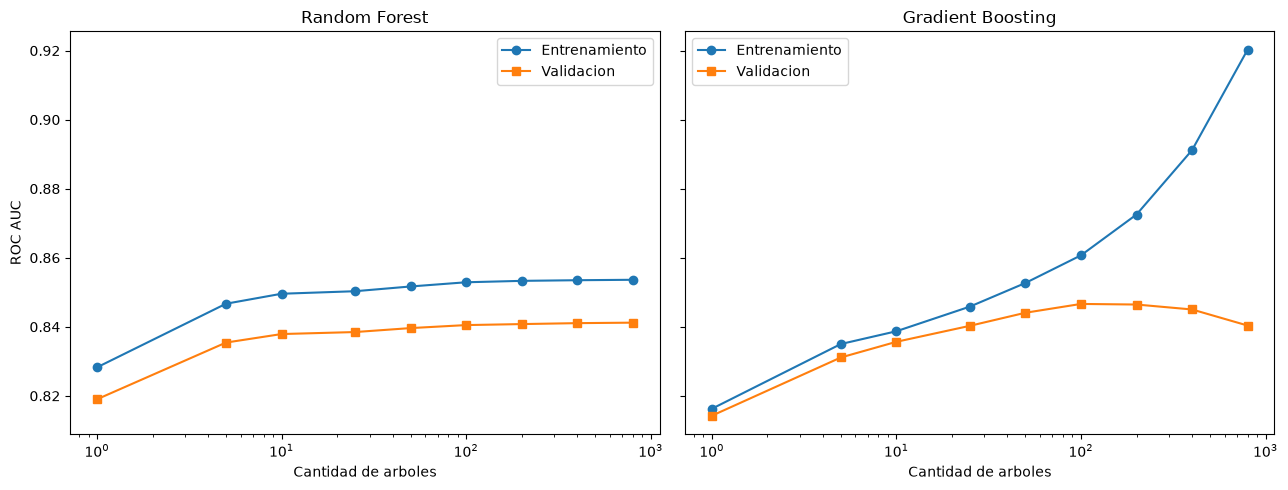

In [37]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    sharey=True
)

axes[0].plot(
    cantidades_arboles,
    auc_rf_train,
    "o-",
    label="Entrenamiento"
)

axes[0].plot(
    cantidades_arboles,
    auc_rf_validacion,
    "s-",
    label="Validacion"
)

axes[0].set_xscale("log")
axes[0].set_title("Random Forest")
axes[0].set_xlabel("Cantidad de arboles")
axes[0].set_ylabel("ROC AUC")
axes[0].legend()

axes[1].plot(
    cantidades_arboles,
    auc_gb_train,
    "o-",
    label="Entrenamiento"
)

axes[1].plot(
    cantidades_arboles,
    auc_gb_validacion,
    "s-",
    label="Validacion"
)

axes[1].set_xscale("log")
axes[1].set_title("Gradient Boosting")
axes[1].set_xlabel("Cantidad de arboles")
axes[1].legend()

plt.tight_layout()
plt.show()

Random Forest se estabiliza al aumentar la cantidad de arboles. Gradient Boosting mejora hasta aproximadamente 100 o 200 arboles y luego comienza a sobreajustar. Por eso no elegimos automaticamente la configuracion con mas arboles.

## 5. Comparacion economica en validacion

ROC AUC no alcanza para elegir el modelo final porque la estrategia utiliza probabilidades para estimar ganancias. Aplicamos la misma regla de seleccion a cada modelo y comparamos capital, ganancia esperada, ganancia real, ROI y defaults.

In [38]:
def evaluar_estrategia(nombre, modelo, presupuesto=2_000_000):
    tabla = validacion_completa[[
        "ID_Solicitud",
        "Monto_Solicitado",
        "Tasa_Interes",
        "Estado_Final"
    ]].copy()

    tabla["probabilidad_pago"] = probabilidades_del_modelo(
        modelo,
        X_validacion
    )

    tabla["ganancia_esperada"] = (
        tabla["probabilidad_pago"]
        * tabla["Monto_Solicitado"]
        * tabla["Tasa_Interes"]
        - (1 - tabla["probabilidad_pago"])
        * tabla["Monto_Solicitado"]
    )

    tabla["retorno_esperado"] = (
        tabla["ganancia_esperada"]
        / tabla["Monto_Solicitado"]
    )

    candidatos = tabla.loc[
        tabla["ganancia_esperada"] > 0
    ].sort_values(
        ["retorno_esperado", "Monto_Solicitado", "ID_Solicitud"],
        ascending=[False, True, True]
    )

    capital = 0
    ids_aprobados = []

    for _, solicitud in candidatos.iterrows():
        monto = solicitud["Monto_Solicitado"]
        if capital + monto <= presupuesto:
            ids_aprobados.append(solicitud["ID_Solicitud"])
            capital += monto

    seleccion = tabla.loc[
        tabla["ID_Solicitud"].isin(ids_aprobados)
    ].copy()

    seleccion["ganancia_real"] = np.where(
        seleccion["Estado_Final"] == 1,
        seleccion["Monto_Solicitado"]
        * seleccion["Tasa_Interes"],
        -seleccion["Monto_Solicitado"]
    )

    ganancia_esperada = seleccion["ganancia_esperada"].sum()
    ganancia_real = seleccion["ganancia_real"].sum()

    return {
        "Modelo": nombre,
        "Prestamos aprobados": len(seleccion),
        "Capital utilizado": capital,
        "Ganancia esperada": ganancia_esperada,
        "Ganancia real": ganancia_real,
        "ROI real": ganancia_real / capital if capital > 0 else 0,
        "Defaults": seleccion["Estado_Final"].eq(0).sum()
    }

comparacion_economica = pd.DataFrame([
    evaluar_estrategia(nombre, modelo)
    for nombre, modelo in modelos_comparados.items()
])

comparacion_economica.sort_values(
    "Ganancia real",
    ascending=False
).reset_index(drop=True).round(4)

,Modelo,Prestamos aprobados,Capital utilizado,Ganancia esperada,Ganancia real,ROI real,Defaults
0,Arbol ajustado,86,2000000.0,574898.9637,637569.86,0.3188,1
1,Red neuronal MLP,84,1999800.0,586408.6163,627674.14,0.3139,0
2,Gradient Boosting,82,1999700.0,547314.8843,612716.50,0.3064,1
3,Bagging,123,1999900.0,550966.1050,594581.52,0.2973,1
4,Random Forest 300,140,1999600.0,486086.6356,573849.81,0.2870,2
5,Random Forest 100,135,1999800.0,489806.1522,571350.73,0.2857,2


## 6. Importancia de las variables

Analizamos las variables utilizadas por Gradient Boosting. Una importancia alta indica que la variable participo en las decisiones del modelo, pero no implica causalidad ni muestra la direccion de su efecto.

In [39]:
preparacion_gradient = gradient_boosting.named_steps[
    "preparacion"
]

modelo_gradient = gradient_boosting.named_steps[
    "modelo"
]

nombres_variables = preparacion_gradient.get_feature_names_out()

importancia_variables = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": modelo_gradient.feature_importances_
})

importancia_variables = importancia_variables.sort_values(
    "Importancia",
    ascending=False
).reset_index(drop=True)

importancia_variables

,Variable,Importancia
0,numericas__atraso_promedio,0.539202
1,numericas__log_ratio_prestamo_saldo,0.322403
2,numericas__log_ratio_prestamo_ingreso,0.028142
3,numericas__atraso_maximo,0.025676
4,numericas__log_ratio_tendencia_saldo,0.023435
5,numericas__Tasa_Interes,0.012403
6,numericas__saldo_promedio,0.011721
7,numericas__saldo_final,0.010435
8,numericas__Monto_Solicitado,0.007964
9,numericas__Ingreso_Mensual,0.005773


## 7. Preparacion de las solicitudes de test

Repetimos la misma preparacion temporal y construimos las mismas variables que en entrenamiento.

In [40]:
solicitudes_test = pd.read_csv("data/solicitudes_test.csv")

solicitudes_test["Fecha_Solicitud"] = pd.to_datetime(
    solicitudes_test["Fecha_Solicitud"]
)

banco_test = comportamiento_bancario.copy()

banco_test["Mes_Referencia"] = pd.to_datetime(
    banco_test["Mes_Referencia"]
)

historial_test = solicitudes_test[[
    "ID_Solicitud",
    "ID_Usuario",
    "Fecha_Solicitud"
]].merge(
    banco_test,
    on="ID_Usuario",
    how="left"
)

# Conservamos unicamente los meses anteriores a la solicitud
historial_test = historial_test.loc[
    historial_test["Mes_Referencia"]
    < historial_test["Fecha_Solicitud"]
].copy()

historial_test = historial_test.sort_values(
    ["ID_Solicitud", "Mes_Referencia"]
)

print("Solicitudes de test:", len(solicitudes_test))
print(
    "Solicitudes con historial anterior:",
    historial_test["ID_Solicitud"].nunique()
)
print(
    "Solicitudes sin historial anterior:",
    len(solicitudes_test)
    - historial_test["ID_Solicitud"].nunique()
)

Solicitudes de test: 3061
Solicitudes con historial anterior: 3061
Solicitudes sin historial anterior: 0


In [41]:
resumen_historial_test = historial_test.groupby("ID_Solicitud").agg(
    meses_historial=("Mes_Referencia", "count"),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean"),
    saldo_inicial=("Saldo_Promedio_Mensual", "first"),
    saldo_final=("Saldo_Promedio_Mensual", "last"),
    atraso_promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    atraso_maximo=("Dias_Atraso_Otras_Deudas", "max")
).reset_index()

datos_test = solicitudes_test.merge(
    resumen_historial_test,
    on="ID_Solicitud",
    how="left",
    validate="one_to_one"
)

# Evitamos dividir por cero
saldo_inicial_seguro_test = datos_test["saldo_inicial"].mask(
    datos_test["saldo_inicial"].eq(0)
)

saldo_promedio_seguro_test = datos_test["saldo_promedio"].mask(
    datos_test["saldo_promedio"].eq(0)
)

datos_test["ratio_tendencia_saldo"] = (
    datos_test["saldo_final"] / saldo_inicial_seguro_test
)

datos_test["ratio_prestamo_ingreso"] = (
    datos_test["Monto_Solicitado"] / datos_test["Ingreso_Mensual"]
)

datos_test["ratio_prestamo_saldo"] = (
    datos_test["Monto_Solicitado"] / saldo_promedio_seguro_test
)

# Las mismas transformaciones usadas en entrenamiento
datos_test["log_ratio_prestamo_ingreso"] = np.log1p(
    datos_test["ratio_prestamo_ingreso"]
)

datos_test["log_ratio_prestamo_saldo"] = np.log1p(
    datos_test["ratio_prestamo_saldo"]
)

datos_test["log_ratio_tendencia_saldo"] = np.log(
    datos_test["ratio_tendencia_saldo"]
)

datos_test = datos_test.drop(columns="saldo_inicial")

# Seleccionamos las mismas columnas y en el mismo orden
X_test = datos_test[X.columns].copy()

print("Solicitudes preparadas:", len(X_test))
print("IDs repetidos:", datos_test["ID_Solicitud"].duplicated().sum())

print("\nValores faltantes:")
print(X_test.isna().sum())

print("\nValores infinitos:")
print(
    np.isinf(
        X_test.select_dtypes(include="number")
    ).sum()
)

Solicitudes preparadas: 3061
IDs repetidos: 0

Valores faltantes:
Monto_Solicitado              0
Tasa_Interes                  0
Ingreso_Mensual               0
Motivo_Prestamo               0
meses_historial               0
saldo_promedio                0
saldo_final                   0
atraso_promedio               0
atraso_maximo                 0
log_ratio_prestamo_ingreso    0
log_ratio_prestamo_saldo      0
log_ratio_tendencia_saldo     0
dtype: int64

Valores infinitos:
Monto_Solicitado              0
Tasa_Interes                  0
Ingreso_Mensual               0
meses_historial               0
saldo_promedio                0
saldo_final                   0
atraso_promedio               0
atraso_maximo                 0
log_ratio_prestamo_ingreso    0
log_ratio_prestamo_saldo      0
log_ratio_tendencia_saldo     0
dtype: int64


## 8. Modelo final y archivo de entrega

La red neuronal MLP obtuvo el mejor ROC AUC de validacion y no registro defaults entre los prestamos seleccionados. Gradient Boosting obtuvo el menor Brier score. Sin embargo, el arbol ajustado produjo la mayor ganancia real y el mejor ROI al aplicar la estrategia sobre validacion.

Como la consigna busca seleccionar prestamos para maximizar la ganancia bajo un presupuesto, elegimos el arbol ajustado como modelo final. Luego lo entrenamos nuevamente con todas las solicitudes disponibles antes de predecir sobre test.

In [42]:
modelo_final = clone(
    arbol_ajustado
)

modelo_final.fit(
    X,
    y
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Monto_Solicitado','Tasa_Interes','Ingreso_Mensual',..., 'log_ratio_prestamo_ingreso','log_ratio_prestamo_saldo', 'log_ratio_tendencia_saldo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('motivo', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [43]:
indice_pagado_final = list(
    modelo_final.named_steps["modelo"].classes_
).index(1)

probabilidades_test_final = (
    modelo_final.predict_proba(X_test)[
        :, indice_pagado_final
    ]
)

In [44]:
resultado_test_final = datos_test[[
    "ID_Solicitud",
    "Monto_Solicitado",
    "Tasa_Interes"
]].copy()

resultado_test_final[
    "probabilidad_pago"
] = probabilidades_test_final

resultado_test_final["ganancia_esperada"] = (
    resultado_test_final["probabilidad_pago"]
    * resultado_test_final["Monto_Solicitado"]
    * resultado_test_final["Tasa_Interes"]
    - (
        1
        - resultado_test_final["probabilidad_pago"]
    )
    * resultado_test_final["Monto_Solicitado"]
)

resultado_test_final["retorno_esperado"] = (
    resultado_test_final["ganancia_esperada"]
    / resultado_test_final["Monto_Solicitado"]
)

resultado_test_final.head(10)

,ID_Solicitud,Monto_Solicitado,Tasa_Interes,probabilidad_pago,ganancia_esperada,retorno_esperado
0,32417,2300,0.2771,0.751527,-92.515743,-0.040224
1,32418,10900,0.3291,0.983386,3346.497643,0.307018
2,32419,1300,0.2485,0.728758,-117.189052,-0.090145
3,32420,1600,0.2699,0.905534,239.899569,0.149937
4,32421,900,0.2317,0.983386,190.112716,0.211236
5,32422,500,0.2436,0.905534,63.060847,0.126122
6,32423,6200,0.2713,0.983386,1551.106268,0.250178
7,32424,1800,0.2749,0.905534,278.036819,0.154465
8,32425,900,0.2033,0.837912,7.433654,0.008260
9,32426,1900,0.2480,0.728758,-171.968627,-0.090510


In [45]:
presupuesto_final = 2_000_000

candidatos_final = resultado_test_final.loc[
    resultado_test_final["ganancia_esperada"] > 0
].sort_values(
    [
        "retorno_esperado",
        "Monto_Solicitado",
        "ID_Solicitud"
    ],
    ascending=[False, True, True]
)

capital_final = 0
ids_aprobados_final = []

for _, solicitud in candidatos_final.iterrows():
    monto = solicitud["Monto_Solicitado"]

    if capital_final + monto <= presupuesto_final:
        ids_aprobados_final.append(
            solicitud["ID_Solicitud"]
        )
        capital_final += monto

resultado_test_final["aprobado"] = (
    resultado_test_final["ID_Solicitud"]
    .isin(ids_aprobados_final)
    .astype(int)
)

seleccion_final = resultado_test_final.loc[
    resultado_test_final["aprobado"] == 1
]

assert len(resultado_test_final) == len(solicitudes_test)
assert resultado_test_final["ID_Solicitud"].is_unique
assert resultado_test_final["ID_Solicitud"].tolist() == (
    solicitudes_test["ID_Solicitud"].tolist()
)
assert resultado_test_final["aprobado"].isin([0, 1]).all()
assert (
    seleccion_final["Monto_Solicitado"].sum()
    <= presupuesto_final
)

print(
    "Solicitudes totales:",
    len(resultado_test_final)
)

print(
    "Prestamos aprobados:",
    len(seleccion_final)
)

print(
    f"Capital aprobado: USD {capital_final:,.2f}"
)

print(
    "Presupuesto restante: "
    f"USD {presupuesto_final - capital_final:,.2f}"
)

print(
    "Ganancia esperada: "
    f"USD {seleccion_final['ganancia_esperada'].sum():,.2f}"
)

Solicitudes totales: 3061
Prestamos aprobados: 618
Capital aprobado: USD 1,999,700.00
Presupuesto restante: USD 300.00
Ganancia esperada: USD 534,862.98


In [46]:
entrega_final = resultado_test_final[
    ["ID_Solicitud", "aprobado"]
].rename(
    columns={
        "aprobado": "Desicion_Aprobacion"
    }
)

assert len(entrega_final) == 3061
assert entrega_final["ID_Solicitud"].is_unique
assert entrega_final[
    "Desicion_Aprobacion"
].isin([0, 1]).all()
assert not entrega_final.isna().any().any()

entrega_final.to_csv(
    "arbol.csv",
    index=False
)

print(
    "Archivo generado:",
    "arbol.csv"
)

print(
    "Aprobados:",
    entrega_final[
        "Desicion_Aprobacion"
    ].sum()
)

entrega_final.head()

Archivo generado: arbol.csv
Aprobados: 618


,ID_Solicitud,Desicion_Aprobacion
0,32417,0
1,32418,1
2,32419,0
3,32420,0
4,32421,0


## 9. Resumen de decisiones

- El arbol sin limite fue descartado por sobreajuste.
- El arbol ajustado quedo como referencia.
- Bagging mejoro al arbol individual.
- Random Forest redujo la correlacion, pero no supero a Bagging.
- Aumentar Random Forest de 100 a 300 arboles produjo una mejora minima.
- Gradient Boosting obtuvo un buen equilibrio entre ROC AUC y Brier score.
- Una cantidad excesiva de arboles produjo sobreajuste en Gradient Boosting.
- La red neuronal MLP obtuvo el mejor ROC AUC y selecciono prestamos sin defaults en validacion.
- El arbol ajustado obtuvo la mayor ganancia real y el mejor ROI en validacion.
- Como el objetivo de la consigna es economico, el arbol ajustado fue elegido como modelo final.
- El modelo elegido se entreno nuevamente con todos los datos antes de predecir test.